# 📝 Reporte de Actividad: Alineación de Recompensas en Aprendizaje por Refuerzo

### 🎯 Objetivo de la Tarea
El objetivo de esta actividad es diagnosticar y corregir un problema de *specification gaming* / *reward hacking* en un entorno de GridWorld. Se analiza cómo un agente de $Q$-learning prefiere explotar un bucle infinito de recolección de monedas en la versión inicial (**V1**) antes que resolver la tarea real de llegar a la meta, y se diseña una nueva especificación de recompensa (**V2**) que alinee perfectamente el comportamiento del agente con el objetivo principal del entorno.

### 👥 Integrantes del Grupo
* **JUANA GABRIELA LOPEZ TREJOS**
* **JUAN JOSE MELO MONTENEGRO**
* **WILSON NAVIA VALENCIA**
* **JAIBER JOHAN OBANDO LOPEZ**
* **EDUARDO SARMIENTO PRADILLA**

---

### 📢 Nota Importante
Las respuestas detalladas a las preguntas teóricas y prácticas de la actividad, así como la explicación profunda de todo el proceso de experimentación, se presentan y responden formalmente en un **documento PDF adjunto por separado con nombre Actividad_lab_specification_gaming_final.pdf**.

In [ ]:
!pip install "gymnasium[box2d]" imageio pillow -q

import numpy as np
import random
import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt

random.seed(0)
np.random.seed(0)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 65.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 59.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 72.3 MB/s eta 0:00:00


### Función Unificada de Configuración
Para evitar conflictos de sincronización, esta función genera la meta y las monedas en un solo paso, asegurando que no haya solapamientos.

In [ ]:
def preparar_tablero_aleatorio(minimo=0, maximo=5, num_monedas=3):
    # 1. Generar meta (que no sea 0,0)
    while True:
        meta_pos = (random.randint(minimo, maximo), random.randint(minimo, maximo))
        if meta_pos != (0, 0):
            break

    # 2. Generar monedas (que no sean 0,0 ni la meta, y distintas entre sí)
    posiciones_monedas = set()
    while len(posiciones_monedas) < num_monedas:
        candidata = (random.randint(minimo, maximo), random.randint(minimo, maximo))
        if candidata != (0, 0) and candidata != meta_pos:
            posiciones_monedas.add(candidata)

    return meta_pos, tuple(posiciones_monedas)

# Ejecución única para sincronizar variables
meta_actual, monedas_actuales = preparar_tablero_aleatorio()

print(f"Configuración del Tablero:")
print(f"- Meta: {meta_actual}")
print(f"- Monedas: {monedas_actuales}")

Configuración del Tablero:
- Meta: (3, 3)
- Monedas: ((0, 2), (3, 2), (4, 3))


In [ ]:
N = 6
#GOAL = (5, 5)
class RewardHackingGridWorld(gym.Env):
    """Gridworld con meta interna para evitar bugs visuales."""
    metadata = {"render_modes": []}

    def __init__(self, goal_position=(5,5), coin_positions=((0, 1), (1, 0), (1, 1)),
                 coin_repeatable=True, coin_reward=1.0, goal_reward=10.0,
                 step_cost=-0.01, max_steps=200):
        super().__init__()
        self.goal_position = goal_position  # Cada instancia guarda su propia meta
        self.coin_positions = set(coin_positions)
        self.coin_repeatable = coin_repeatable
        self.coin_reward = coin_reward
        self.goal_reward = goal_reward
        self.step_cost = step_cost
        self.max_steps = max_steps

        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.Discrete(N * N)

        self._pos = (0, 0)
        self._steps = 0
        self._collected = set()
        self._last_coin_hit = False

    def _obs(self):
        r, c = self._pos
        return r * N + c

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self._pos = (0, 0)
        self._steps = 0
        self._collected = set()
        self._last_coin_hit = False
        return self._obs(), {}

    def step(self, action):
        r, c = self._pos
        if action == 0:   r = max(0, r - 1)
        elif action == 1: r = min(N - 1, r + 1)
        elif action == 2: c = max(0, c - 1)
        elif action == 3: c = min(N - 1, c + 1)

        self._pos = (r, c)
        self._steps += 1
        reward = self.step_cost
        self._last_coin_hit = False

        if self._pos in self.coin_positions:
            if self.coin_repeatable or self._pos not in self._collected:
                reward += self.coin_reward
                self._collected.add(self._pos)
                self._last_coin_hit = True

        terminated = self._pos == self.goal_position
        if terminated:
            reward += self.goal_reward

        truncated = self._steps >= self.max_steps
        return self._obs(), reward, terminated, truncated, {"is_success": terminated}

## 3. El agente: Q-learning tabular

No necesitas modificar esta celda. El agente mantiene una tabla `Q(estado, acción)` que va ajustando cada vez que prueba algo y observa el resultado — igual que en la lectura previa.

In [ ]:
class QLearningAgent:
    def __init__(self, n_states, n_actions, alpha=0.1, gamma=0.95,
                 epsilon_start=1.0, epsilon_end=0.05, epsilon_decay_episodes=1500):
        # La "tabla Q": una fila por cada estado posible (36 casillas), una columna por cada
        # acción posible (4). Q[s, a] = "qué tan buena creo que es la acción a en el estado s".
        # Empieza en ceros porque el agente no sabe nada todavía.
        self.q = np.zeros((n_states, n_actions))

        self.alpha = alpha       # "tasa de aprendizaje": qué tanto ajusta su creencia con cada experiencia
                                  # (0.1 = ajusta poco a poco, no le cree del todo a un solo resultado)
        self.gamma = gamma       # "factor de descuento": qué tanto valora la recompensa futura vs la inmediata
                                  # (0.95 = casi tanto, mira bastante hacia adelante)

        # --- parámetros de exploración vs explotación (ver método epsilon() de abajo) ---
        self.epsilon_start = epsilon_start              # al principio explora casi siempre (1.0 = 100%)
        self.epsilon_end = epsilon_end                  # al final casi no explora (0.05 = 5% de las veces)
        self.epsilon_decay_episodes = epsilon_decay_episodes  # en cuántos episodios pasa de "start" a "end"

    def epsilon(self, episode):
        # Calcula qué tan "explorador" es el agente en este punto del entrenamiento.
        # Va bajando linealmente de epsilon_start a epsilon_end a medida que pasan los episodios.
        frac = min(1.0, episode / self.epsilon_decay_episodes)  # progreso del entrenamiento, entre 0 y 1
        return self.epsilon_start + frac * (self.epsilon_end - self.epsilon_start)

    def act(self, state, episode):
        # Decide qué acción tomar en el estado actual. Esto es "epsilon-greedy":
        if random.random() < self.epsilon(episode):
            # EXPLORAR: con probabilidad epsilon, elige una acción totalmente al azar.
            # Esto es necesario para que el agente descubra cosas nuevas (como las monedas).
            return random.randint(0, self.q.shape[1] - 1)
        # EXPLOTAR: si no, elige la acción que según su tabla Q es la mejor hasta ahora.
        return int(np.argmax(self.q[state]))

    def update(self, s, a, r, s_next, done):
        # Esta es la fórmula de Q-learning: ajusta Q[s,a] hacia el "target" (lo que debería valer).

        # target = la recompensa que acabo de recibir, más (si el episodio no terminó) el valor
        # que creo que tiene el MEJOR movimiento posible desde el siguiente estado.
        target = r + (0 if done else self.gamma * np.max(self.q[s_next]))

        # Muevo mi creencia actual Q[s,a] un poquito (alpha) hacia ese target.
        # Si target > Q[s,a], la subo un poco; si es menor, la bajo un poco.
        self.q[s, a] += self.alpha * (target - self.q[s, a])


def train(env, n_episodes=2000):
    # Crea un agente nuevo, con una tabla Q del tamaño exacto que necesita este entorno
    # (env.observation_space.n = 36 estados, env.action_space.n = 4 acciones).
    agent = QLearningAgent(env.observation_space.n, env.action_space.n,
                            epsilon_decay_episodes=int(n_episodes * 0.75))

    reached_goal, ep_rewards = [], []  # aquí vamos guardando estadísticas de cada episodio

    for ep in range(n_episodes):          # repite el entrenamiento n_episodes veces (por defecto 2000)
        s, info = env.reset()             # empieza un episodio nuevo, agente vuelve a la casilla inicial
        done, total_r, goal_hit = False, 0, False

        while not done:                   # se repite hasta que el episodio termine (llegó a la meta o se acabó el tiempo)
            a = agent.act(s, ep)          # el agente elige una acción (al azar o la mejor que conoce)

            s_next, r, terminated, truncated, info = env.step(a)  # el entorno ejecuta esa acción
            done = terminated or truncated                        # el episodio acaba por cualquiera de las dos razones

            agent.update(s, a, r, s_next, done)  # el agente aprende de lo que acaba de pasar

            s = s_next        # nos movemos al nuevo estado para la siguiente vuelta del while
            total_r += r      # acumulamos la recompensa total del episodio

            if terminated:
                goal_hit = True   # marcamos que sí llegó a la meta (para las estadísticas)

        # al terminar el episodio, guardamos si llegó a la meta (1 o 0) y cuánta recompensa acumuló
        reached_goal.append(1 if goal_hit else 0)
        ep_rewards.append(total_r)

    return agent, reached_goal, ep_rewards

## 4. Herramientas de visualización

Corre esta celda tal cual — la vas a usar varias veces.

In [ ]:
# Diccionario que traduce cada acción (0,1,2,3) en un pequeño desplazamiento (dx, dy) para dibujar
# una flecha. OJO: en matplotlib el eje Y crece hacia ARRIBA, pero nosotros pensamos "fila 0 = arriba"
# como en una matriz normal (fila 0 = arriba, fila 5 = abajo) — por eso más abajo volteamos las filas
# al dibujar. Aquí, dy positivo = flecha hacia arriba en el dibujo.
ARROWS = {
    0: (0, 0.3),    # arriba     -> flecha apunta hacia arriba
    1: (0, -0.3),   # abajo      -> flecha apunta hacia abajo
    2: (-0.3, 0),   # izquierda  -> flecha apunta a la izquierda
    3: (0.3, 0),    # derecha    -> flecha apunta a la derecha
}

def render_policy(agent, env, title=""):
    # Dibuja el tablero completo con una flecha en cada casilla mostrando qué acción
    # el agente cree que es la mejor ahí (según su tabla Q ya entrenada).

    fig, ax = plt.subplots(figsize=(5, 5))  # crea una figura cuadrada de 5x5 pulgadas

    # --- dibuja las líneas de la cuadrícula, casilla por casilla ---
    for r in range(N):
        for c in range(N):
            # "N - 1 - r" voltea la fila: así la fila 0 (inicio, en nuestra cabeza) queda ARRIBA
            # en el dibujo, aunque matplotlib normalmente dibuja desde abajo hacia arriba.
            ax.add_patch(plt.Rectangle((c, N - 1 - r), 1, 1, fill=False, edgecolor="gray"))

    # --- pinta las casillas de moneda en dorado, con un "$" en el centro ---
    for (r, c) in env.coin_positions:
        ax.add_patch(plt.Rectangle((c, N - 1 - r), 1, 1, facecolor="gold", alpha=0.5))
        ax.text(c + 0.5, N - 1 - r + 0.5, "$", ha="center", va="center", fontsize=14)

    # --- pinta la casilla meta en verde, con el texto "META" ---
    # CORRECCIÓN: Usamos la meta interna de la instancia del entorno, no la variable global GOAL
    gr, gc = env.goal_position
    ax.add_patch(plt.Rectangle((gc, N - 1 - gr), 1, 1, facecolor="green", alpha=0.5))
    ax.text(gc + 0.5, N - 1 - gr + 0.5, "META", ha="center", va="center", fontsize=8)

    # --- marca la casilla de inicio (0,0) con una "S" azul ---
    ax.text(0.5, N - 1 + 0.5, "S", ha="center", va="center", fontsize=10, color="blue")

    # --- dibuja una flecha en cada casilla, según la mejor acción que el agente aprendió ---
    for r in range(N):
        for c in range(N):
            s = r * N + c                        # convierte (fila, columna) al mismo id de estado que usa el agente
            a = int(np.argmax(agent.q[s]))        # "argmax" = la acción con el valor Q más alto para este estado
            dx, dy = ARROWS[a]                    # traduce esa acción a un desplazamiento (dx, dy) para dibujar
            ax.arrow(c + 0.5, N - 1 - r + 0.5,     # el centro de la casilla (con la misma volteada de filas)
                      dx, dy, head_width=0.12, color="black")

    # --- ajustes finales de la vista: sin ejes numéricos, con el título que le pasemos ---
    ax.set_xlim(0, N); ax.set_ylim(0, N)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title)
    plt.show()


def moving_avg(x, w=50):
    # Calcula el promedio móvil de una lista (suaviza una curva ruidosa).
    # Por ejemplo, si w=50, cada punto de salida es el promedio de los 50 valores anteriores.
    # Esto es lo que hace que la curva de entrenamiento se vea como una línea suave y no
    # como un zigzag de puros 0s y 1s (ya que "reached_goal" es una lista de 0/1 por episodio).
    x = np.array(x, dtype=float)
    return np.convolve(x, np.ones(w) / w, mode="valid")  # convolución = forma rápida de hacer promedios deslizantes


def plot_training_curves(curves_dict):
    # Dibuja una o varias curvas de entrenamiento en la misma gráfica, para comparar.
    # curves_dict es un diccionario tipo {"nombre de la curva": lista_de_reached_goal}.
    plt.figure(figsize=(6, 4))
    for label, reached in curves_dict.items():
        plt.plot(moving_avg(reached), label=label)   # una línea por cada entrada del diccionario
    plt.xlabel("Episodio")
    plt.ylabel("% de episodios que llegan a la meta\n(promedio móvil)")
    plt.legend()       # muestra qué línea es cuál (usando los "label" de arriba)
    plt.tight_layout()
    plt.show()

## 3.1 Grabar un video del agente jugando

Igual que hicimos con LunarLander, le agregamos un `render()` real al entorno para poder ver al
agente moverse — no solo las flechas de la política, sino un video del episodio completo, casilla
por casilla. No necesitas modificar esta celda.


In [ ]:
from PIL import Image, ImageDraw
import imageio
from IPython.display import Video

CELL = 64

def render_frame(env):
    # Ahora usamos env.goal_position en lugar de la variable global GOAL
    img = Image.new("RGB", (N * CELL, N * CELL), (255, 255, 255))
    draw = ImageDraw.Draw(img)

    for r in range(N):
        for c in range(N):
            x0, y0 = c * CELL, r * CELL
            draw.rectangle([x0, y0, x0 + CELL, y0 + CELL], outline=(210, 210, 210))

    for (r, c) in env.coin_positions:
        x0, y0 = c * CELL, r * CELL
        hit = (r, c) == env._pos and env._last_coin_hit
        fill = (255, 150, 60) if hit else (255, 210, 90)
        draw.rectangle([x0 + 2, y0 + 2, x0 + CELL - 2, y0 + CELL - 2], fill=fill)
        draw.text((x0 + CELL / 2 - 4, y0 + CELL / 2 - 7), "$", fill=(110, 80, 0))

    # DIBUJO DE LA META USANDO LA POSICIÓN INTERNA DEL ENTORNO
    gr, gc = env.goal_position
    x0, y0 = gc * CELL, gr * CELL
    draw.rectangle([x0 + 2, y0 + 2, x0 + CELL - 2, y0 + CELL - 2], fill=(160, 220, 140))
    draw.text((x0 + 6, y0 + CELL / 2 - 6), "META", fill=(20, 70, 20))

    draw.text((6, 4), "S", fill=(30, 60, 160))

    r, c = env._pos
    x0, y0 = c * CELL, r * CELL
    pad = 10
    draw.ellipse([x0 + pad, y0 + pad, x0 + CELL - pad, y0 + CELL - pad], fill=(40, 100, 210))

    return np.array(img)

def record_episode_video(env, agent, filename, max_frames=150, fps=6):
    frames = []
    obs, info = env.reset()
    frames.append(render_frame(env))

    done, steps = False, 0
    while not done and steps < max_frames:
        action = int(np.argmax(agent.q[obs]))
        obs, reward, terminated, truncated, info = env.step(action)
        frames.append(render_frame(env))
        done = terminated or truncated
        steps += 1

    imageio.mimsave(filename, frames, fps=fps)
    return Video(filename, embed=True)

---
## Parte 1 — Entrenar con la recompensa mal especificada

Esta es la configuración "trampa": las monedas se pueden recoger **una y otra vez**
(`coin_repeatable=True`) y el agente tiene **200 pasos** por episodio para explorar. Nadie diseñó
esto para que fallara "por accidente" — es exactamente el tipo de error de especificación que
ocurre en la práctica: alguien piensa *"vamos a darle un pequeño incentivo extra cerca del inicio
para que explore"* sin notar que ese incentivo, acumulado muchas veces, puede superar por mucho la
recompensa de la tarea real.


In [ ]:
env_v1 = RewardHackingGridWorld(
    coin_positions=((0, 1), (1, 0), (1, 1)),  # las 3 monedas están cerca del inicio (0,0), no en el camino a la meta
    coin_repeatable=True,    # <- LA CLAVE DEL PROBLEMA: se pueden recoger una y otra vez, infinitas veces
    coin_reward=1.0,         # cada vez que pisa una moneda, +1 de recompensa
    goal_reward=10.0,        # llegar a la meta da +10, pero solo se cobra UNA vez por episodio
    step_cost=-0.01,         # cada paso cuesta casi nada (-0.01), así que deambular sale muy barato
    max_steps=200,           # <- TAMBIÉN CLAVE: tiene 200 pasos para explorar, de sobra para "vivir" de las monedas
  )
# Con estos números: si el agente se queda saltando entre las 3 monedas, en 200 pasos puede sacar
# muchísimo más que 10 puntos. Por eso esta configuración está "mal especificada" a propósito.

agent_v1, reached_v1, rewards_v1 = train(env_v1, n_episodes=2000)
# Entrena a un agente de Q-learning nuevo en este entorno, dejándolo jugar 2000 episodios completos.
# Devuelve:
#   agent_v1   -> el agente ya entrenado, con su tabla Q llena de lo que aprendió
#   reached_v1 -> una lista de 2000 unos y ceros: 1 si ese episodio SÍ llegó a la meta, 0 si no
#   rewards_v1 -> una lista de 2000 números: la recompensa TOTAL acumulada en cada episodio

print(f"% de episodios (ultimos 200) que llegaron a la meta: {100*np.mean(reached_v1[-200:]):.1f}%")
# reached_v1[-200:]  -> toma solo los últimos 200 episodios (cuando el agente ya terminó de aprender,
#                       no los primeros que son puro ensayo y error al azar)
# np.mean(...)       -> promedio de esos 0s y 1s = proporción que sí llegó a la meta
# *100               -> lo convierte a porcentaje
# Este número es la prueba del "hackeo": va a salir muy bajo (0-5%) aunque haya entrenado 2000 episodios.

print(f"Recompensa promedio por episodio (ultimos 200):      {np.mean(rewards_v1[-200:]):.2f}")
# Aquí está la trampa visual: este número puede salir ALTO (recompensa acumulada grande),
# precisamente porque el agente aprendió a "farmear" monedas — tiene mucha recompensa numérica
# pero casi nunca resuelve la tarea real. Es el contraste que van a discutir con el grupo.

% de episodios (ultimos 200) que llegaron a la meta: 0.0%
Recompensa promedio por episodio (ultimos 200):      188.09


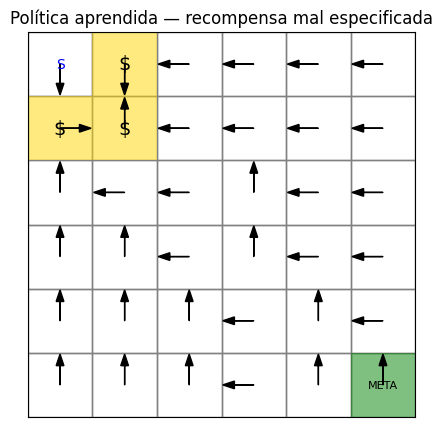

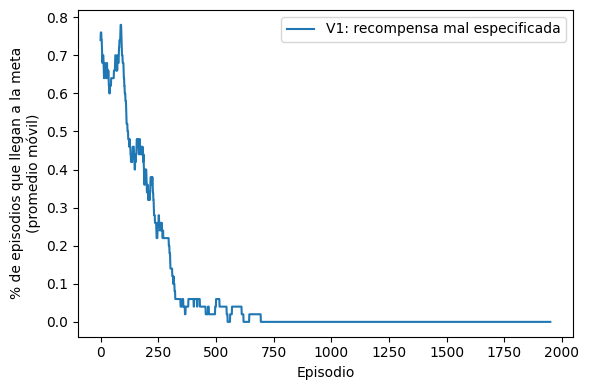

In [ ]:
render_policy(agent_v1, env_v1, "Política aprendida — recompensa mal especificada")
# Dibuja el tablero con una flecha en cada casilla, mostrando qué acción cree el agente
# que es la mejor ahí (según su tabla Q ya entrenada, agent_v1.q).
# Lo que vas a VER: las flechas cerca del inicio van a apuntar entre sí, formando un
# pequeño ciclo alrededor de las monedas — el agente literalmente dibuja su propia trampa.
# Las flechas lejos del inicio probablemente sean casi al azar, porque el agente casi nunca
# llegó a explorar esa parte del tablero (no le convenía irse hasta allá).

plot_training_curves({"V1: recompensa mal especificada": reached_v1})
# Dibuja la curva de "% de episodios que llegan a la meta" a lo largo del entrenamiento.
# El diccionario {"nombre": lista} es porque plot_training_curves puede dibujar varias
# curvas a la vez (más adelante van a comparar V1 vs V2 en la misma gráfica); aquí solo
# le pasamos una.
# Lo que vas a VER: la curva empieza relativamente alta (el agente llega a la meta por puro
# azar al principio, cuando explora mucho) y va BAJANDO conforme entrena más — la prueba
# visual de que "aprender más" lo alejó del objetivo real, no lo acercó.

Ahora véanlo en video — el agente jugando un episodio completo con la política ya aprendida:

In [ ]:
record_episode_video(env_v1, agent_v1, "agente_v1.mp4", max_frames=env_v1.max_steps, fps=6)


# Cambios en la especificacion de la recompenza

## 1. Coin_repeatable = False

In [ ]:
env_v11 = RewardHackingGridWorld(
    coin_positions=((0, 1), (1, 0), (1, 1)),  # las 3 monedas están cerca del inicio (0,0), no en el camino a la meta
    coin_repeatable=False,    # <- LA CLAVE DEL PROBLEMA: se pueden recoger una y otra vez, infinitas veces
    coin_reward=1.0,         # cada vez que pisa una moneda, +1 de recompensa
    goal_reward=10.0,        # llegar a la meta da +10, pero solo se cobra UNA vez por episodio
    step_cost=-0.01,         # cada paso cuesta casi nada (-0.01), así que deambular sale muy barato
    max_steps=200,           # <- TAMBIÉN CLAVE: tiene 200 pasos para explorar, de sobra para "vivir" de las monedas

)

agent_v11, reached_v11, rewards_v11 = train(env_v11, n_episodes=2000)

print(f"% de episodios (ultimos 200) que llegaron a la meta: {100*np.mean(reached_v11[-200:]):.1f}%")

print(f"Recompensa promedio por episodio (ultimos 200):      {np.mean(rewards_v11[-200:]):.2f}")

% de episodios (ultimos 200) que llegaron a la meta: 100.0%
Recompensa promedio por episodio (ultimos 200):      11.90


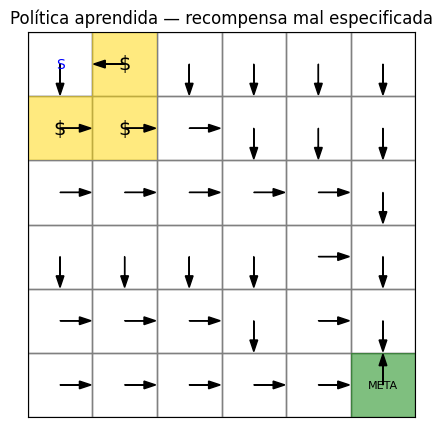

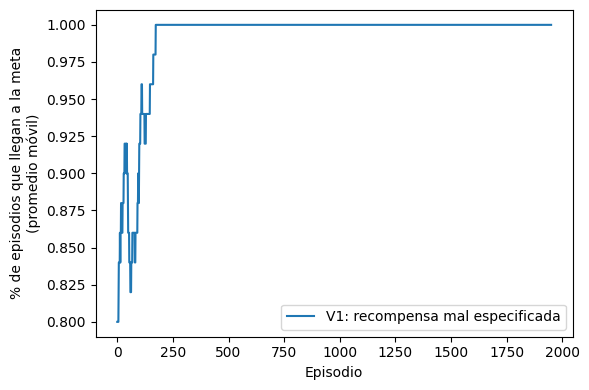

In [ ]:
render_policy(agent_v11, env_v11, "Política aprendida — recompensa mal especificada")
plot_training_curves({"V1: recompensa mal especificada": reached_v11})


In [ ]:
record_episode_video(env_v11, agent_v11, "agente_v11.mp4", max_frames=env_v11.max_steps, fps=6)

## 2. Coin_reward = 0.5


In [ ]:
env_v12 = RewardHackingGridWorld(
    coin_positions=((0, 1), (1, 0), (1, 1)),  # las 3 monedas están cerca del inicio (0,0), no en el camino a la meta
    coin_repeatable=True,    # <- LA CLAVE DEL PROBLEMA: se pueden recoger una y otra vez, infinitas veces
    coin_reward=0.5,         # cada vez que pisa una moneda, +1 de recompensa
    goal_reward=10.0,        # llegar a la meta da +10, pero solo se cobra UNA vez por episodio
    step_cost=-0.01,         # cada paso cuesta casi nada (-0.01), así que deambular sale muy barato
    max_steps=200,           # <- TAMBIÉN CLAVE: tiene 200 pasos para explorar, de sobra para "vivir" de las monedas
)

agent_v12, reached_v12, rewards_v12 = train(env_v11, n_episodes=2000)

print(f"% de episodios (ultimos 200) que llegaron a la meta: {100*np.mean(reached_v12[-200:]):.1f}%")
print(f"Recompensa promedio por episodio (ultimos 200):      {np.mean(rewards_v12[-200:]):.2f}")

% de episodios (ultimos 200) que llegaron a la meta: 100.0%
Recompensa promedio por episodio (ultimos 200):      11.90


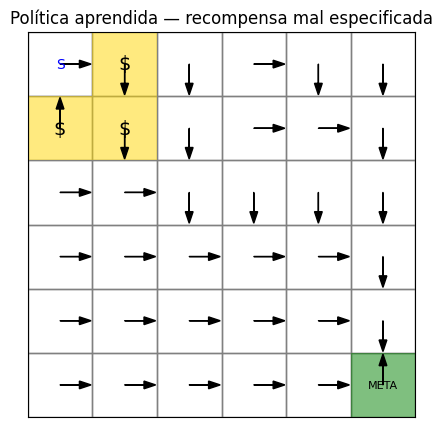

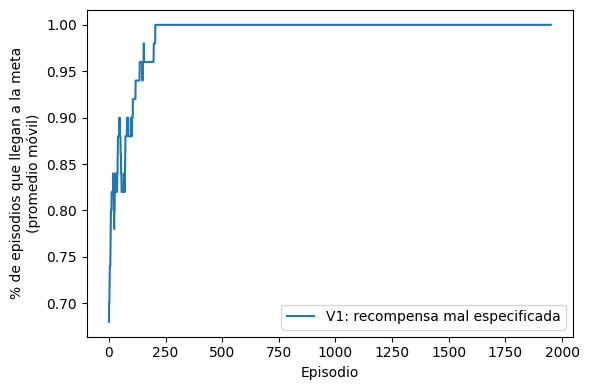

In [ ]:
render_policy(agent_v12, env_v12, "Política aprendida — recompensa mal especificada")
plot_training_curves({"V1: recompensa mal especificada": reached_v12})


In [ ]:
record_episode_video(env_v12, agent_v12, "agente_v12.mp4", max_frames=env_v12.max_steps, fps=6)

## 3. goal_reward = 20


In [ ]:
env_v13 = RewardHackingGridWorld(
    coin_positions=((0, 1), (1, 0), (1, 1)),  # las 3 monedas están cerca del inicio (0,0), no en el camino a la meta
    coin_repeatable=True,    # <- LA CLAVE DEL PROBLEMA: se pueden recoger una y otra vez, infinitas veces
    coin_reward=1.0,         # cada vez que pisa una moneda, +1 de recompensa
    goal_reward=20.0,        # llegar a la meta da +10, pero solo se cobra UNA vez por episodio
    step_cost=-0.01,         # cada paso cuesta casi nada (-0.01), así que deambular sale muy barato
    max_steps=200,           # <- TAMBIÉN CLAVE: tiene 200 pasos para explorar, de sobra para "vivir" de las monedas
)

agent_v13, reached_v13, rewards_v13 = train(env_v13, n_episodes=2000)

print(f"% de episodios (ultimos 200) que llegaron a la meta: {100*np.mean(reached_v13[-200:]):.1f}%")
print(f"Recompensa promedio por episodio (ultimos 200):      {np.mean(rewards_v13[-200:]):.2f}")

% de episodios (ultimos 200) que llegaron a la meta: 0.5%
Recompensa promedio por episodio (ultimos 200):      186.53


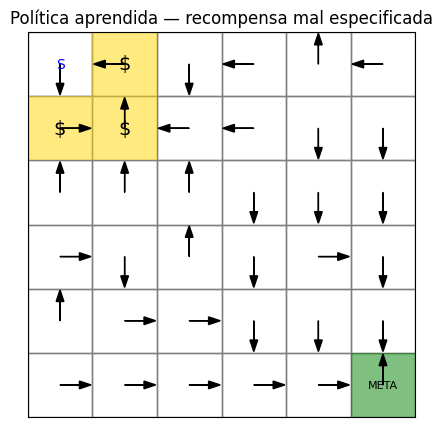

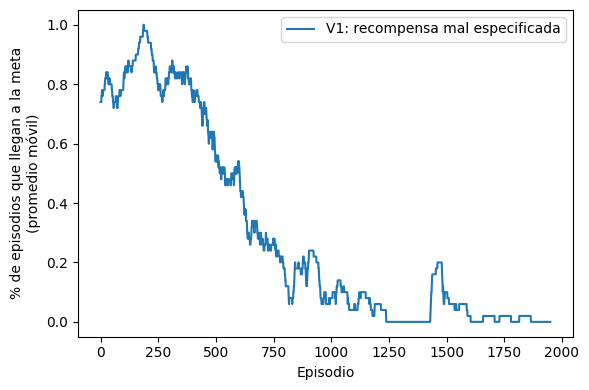

In [ ]:
render_policy(agent_v13, env_v13, "Política aprendida — recompensa mal especificada")
plot_training_curves({"V1: recompensa mal especificada": reached_v13})

In [ ]:
record_episode_video(env_v13, agent_v13, "agente_v13.mp4", max_frames=env_v13.max_steps, fps=6)

## 4. STEP_COST = -0.5

In [ ]:
env_v14 = RewardHackingGridWorld(
    coin_positions=((0, 1), (1, 0), (1, 1)),  # las 3 monedas están cerca del inicio (0,0), no en el camino a la meta
    coin_repeatable=True,    # <- LA CLAVE DEL PROBLEMA: se pueden recoger una y otra vez, infinitas veces
    coin_reward=1.0,         # cada vez que pisa una moneda, +1 de recompensa
    goal_reward=10.0,        # llegar a la meta da +10, pero solo se cobra UNA vez por episodio
    step_cost=-0.5,         # cada paso cuesta casi nada (-0.01), así que deambular sale muy barato
    max_steps=200,           # <- TAMBIÉN CLAVE: tiene 200 pasos para explorar, de sobra para "vivir" de las monedas
)

agent_v14, reached_v14, rewards_v14 = train(env_v14, n_episodes=2000)

print(f"% de episodios (ultimos 200) que llegaron a la meta: {100*np.mean(reached_v14[-200:]):.1f}%")

print(f"Recompensa promedio por episodio (ultimos 200):      {np.mean(rewards_v14[-200:]):.2f}")

% de episodios (ultimos 200) que llegaron a la meta: 0.0%
Recompensa promedio por episodio (ultimos 200):      93.97


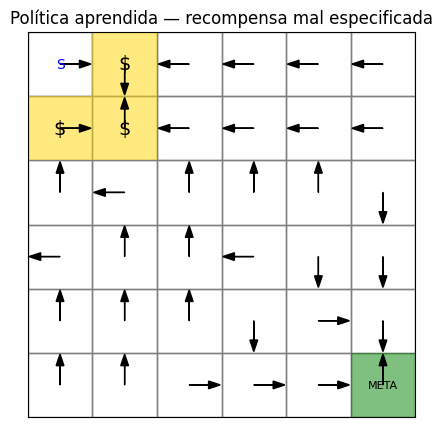

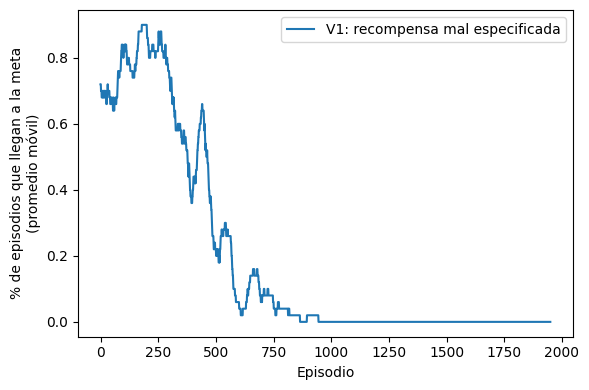

In [ ]:
render_policy(agent_v14, env_v14, "Política aprendida — recompensa mal especificada")
plot_training_curves({"V1: recompensa mal especificada": reached_v14})

In [ ]:
record_episode_video(env_v14, agent_v14, "agente_v14.mp4", max_frames=env_v14.max_steps, fps=6)

## 5. max_step= 50

In [ ]:
env_v15 = RewardHackingGridWorld(
    coin_positions=((0, 1), (1, 0), (1, 1)),  # las 3 monedas están cerca del inicio (0,0), no en el camino a la meta
    coin_repeatable=True,    # <- LA CLAVE DEL PROBLEMA: se pueden recoger una y otra vez, infinitas veces
    coin_reward=1.0,         # cada vez que pisa una moneda, +1 de recompensa
    goal_reward=10.0,        # llegar a la meta da +10, pero solo se cobra UNA vez por episodio
    step_cost=-0.01,         # cada paso cuesta casi nada (-0.01), así que deambular sale muy barato
    max_steps=50,           # <- TAMBIÉN CLAVE: tiene 200 pasos para explorar, de sobra para "vivir" de las monedas
)

agent_v15, reached_v15, rewards_v15 = train(env_v15, n_episodes=2000)

print(f"% de episodios (ultimos 200) que llegaron a la meta: {100*np.mean(reached_v15[-200:]):.1f}%")

print(f"Recompensa promedio por episodio (ultimos 200):      {np.mean(rewards_v15[-200:]):.2f}")

% de episodios (ultimos 200) que llegaron a la meta: 0.0%
Recompensa promedio por episodio (ultimos 200):      46.79


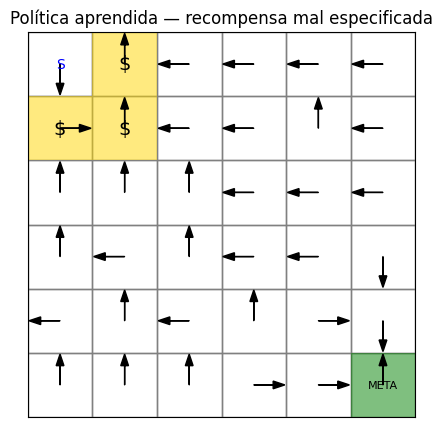

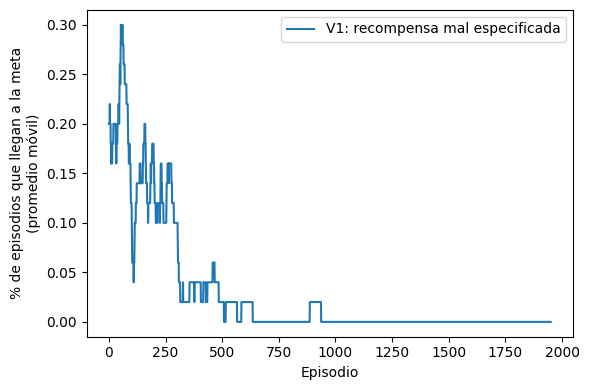

In [ ]:
render_policy(agent_v15, env_v15, "Política aprendida — recompensa mal especificada")
plot_training_curves({"V1: recompensa mal especificada": reached_v15})

In [ ]:
record_episode_video(env_v15, agent_v15, "agente_v15.mp4", max_frames=env_v15.max_steps, fps=6)

---
## Parte 2 — Arreglen la recompensa

Ahora les toca a ustedes. **No cambien la clase `RewardHackingGridWorld` ni el agente** — el
ejercicio es puramente sobre **diseño de la función de recompensa**, que es justamente el tipo de
decisión que en la práctica toman los equipos que entrenan sistemas de IA.

Abajo tienen una plantilla en blanco (`env_v2`). Algunas ideas que pueden probar (no tienen que
usarlas todas, prueben, midan, iteren):

- Hacer que las monedas **no sean repetibles** (`coin_repeatable=False`) — una vez recogidas, se acabaron.
- Reducir el número de pasos por episodio (`max_steps`) para que "quedarse dando vueltas" ya no sea rentable.
- Subir mucho `goal_reward` en relación a lo máximo que se puede sacar de las monedas.
- Aumentar el costo por paso (`step_cost` más negativo) para penalizar deambular.
- Quitar las monedas por completo y ver qué tan rápido/lento aprende el agente sin ninguna señal intermedia
  (esto ilustra el trade-off opuesto: recompensas *demasiado* dispersas también son difíciles de aprender).

**Regla del ejercicio:** no vale simplemente "hacer trampa" apagando las monedas a cero Y bajando el
horizonte a 1 paso — el reto es encontrar una configuración donde las monedas *sigan existiendo como
incentivo* pero el agente igual aprenda a resolver la tarea real.


In [ ]:
# TODO: modifica estos valores. Corre esta celda y la siguiente cuantas veces
# necesites para iterar.

env_v2 = RewardHackingGridWorld(
    coin_positions=((0, 1), (1, 0), (1, 1)),  # no la toques: son las posiciones fijas de las 3 monedas

    coin_repeatable=False,
    # ¿se puede recoger la misma moneda muchas veces?
    # Valores posibles: True o False
    #   True  -> moneda infinita, se puede "farmear" para siempre (así estaba en V1, la version rota)
    #   False -> una vez que la pisas, se agota; ya no vuelve a dar recompensa en ese episodio

    coin_reward=1,
    # cuánta recompensa da pisar UNA moneda (una sola vez, o cada vez, según coin_repeatable)
    # Valores posibles: cualquier numero >= 0 (ej: 0, 0.5, 1.0, 2.0...)
    #   0    -> las monedas no sirven de nada
    #   alto -> más tentador quedarse recolectando en vez de ir a la meta

    goal_reward=25,
    # cuánta recompensa da llegar a la meta (esta SIEMPRE se cobra una sola vez por episodio)
    # Valores posibles: cualquier numero positivo (ej: 5, 10, 20...)
    #   entre más alto, más "vale la pena" para el agente cruzar todo el tablero hasta la meta

    step_cost=-1,
    # cuánto "cuesta" cada paso que da el agente (normalmente negativo, como un peaje)
    # Valores posibles: 0 o negativo (ej: 0, -0.01, -0.05, -0.1...)
    #   mientras mas negativo, mas caro le sale al agente quedarse dando vueltas sin avanzar

    max_steps=500,
    # cuántos pasos como maximo dura un episodio antes de cortarlo a la fuerza (truncated=True)
    # Valores posibles: cualquier entero positivo (ej: 20, 40, 100, 200...)
    #   pocos pasos -> el agente no alcanza a "explotar" tanto un ciclo de monedas
    #   muchos pasos -> le da tiempo de sobra para quedarse rentando en el ciclo
)



agent_v2, reached_v2, rewards_v2 = train(env_v2, n_episodes=2000)

print(f"% de episodios (ultimos 200) que llegaron a la meta: {100*np.mean(reached_v2[-200:]):.1f}%")
print(f"Recompensa promedio por episodio (ultimos 200):      {np.mean(rewards_v2[-200:]):.2f}")

% de episodios (ultimos 200) que llegaron a la meta: 100.0%
Recompensa promedio por episodio (ultimos 200):      16.51


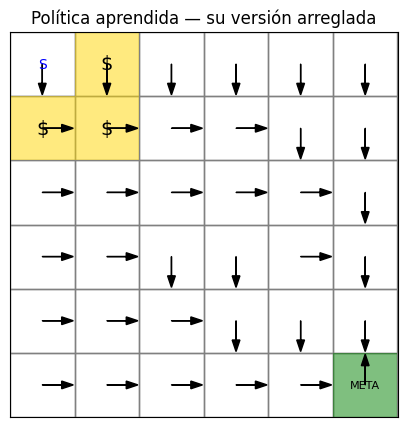

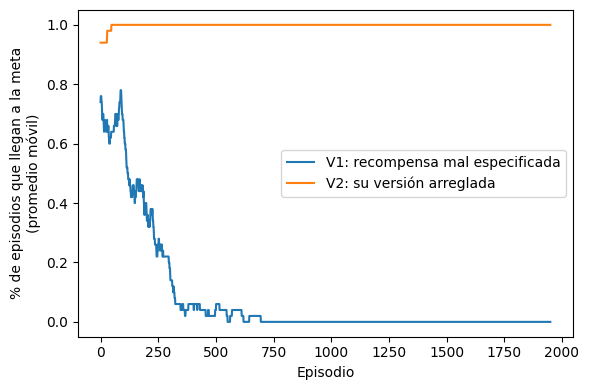

In [ ]:
render_policy(agent_v2, env_v2, "Política aprendida — su versión arreglada")

plot_training_curves({
    "V1: recompensa mal especificada": reached_v1,
    "V2: su versión arreglada": reached_v2,
})

In [ ]:
record_episode_video(env_v2, agent_v2, "agente_v2.mp4", max_frames=env_v2.max_steps, fps=6)


### Comparativa: Recompensa Mal Especificada vs. Bien Especificada (Meta Aleatoria)

En esta sección generamos una meta y posiciones de monedas completamente al azar para entrenar y evaluar ambos agentes.

**¿Qué demuestra este apartado?**
Este experimento es crítico para verificar la **generalización y robustez del diseño de recompensas V2**. Demuestra que la solución implementada en V2 no es simplemente un "parche" o un ajuste de hiperparámetros específico (overfitting) para el mapa fijo de la versión original. Al variar dinámicamente las coordenadas de la meta y las monedas, validamos que:
1. El agente bajo la configuración **V2** sigue convergiendo consistentemente al **100% de éxito** sin importar la aleatoriedad espacial del entorno.
2. El agente bajo la configuración **V1** sigue sufriendo de *reward hacking* e ineficiencia severa en cualquier topología, confirmando que el fallo de la V1 era estructural y que la solución de la V2 es una corrección robusta y de propósito general.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


--- EXPERIMENTO: CASO FIJO (Meta: (5, 5)) ---
V1 (Hacking) - Monedas: ((0, 1), (1, 0), (1, 1))
% de episodios (ultimos 200) que llegaron a la meta: 0.0%
Recompensa promedio por episodio (ultimos 200):      186.12

V2 (Arreglado) - Monedas: ((0, 1), (1, 0), (1, 1))
% de episodios (ultimos 200) que llegaron a la meta: 100.0%
Recompensa promedio por episodio (ultimos 200):      26.47

--- EXPERIMENTO: CASO ALEATORIO (Meta: (3, 3)) ---
V1 (Hacking) - Monedas: ((0, 2), (3, 2), (4, 3))
% de episodios (ultimos 200) que llegaron a la meta: 0.0%
Recompensa promedio por episodio (ultimos 200):      186.24

V2 (Arreglado) - Monedas: ((0, 2), (3, 2), (4, 3))
% de episodios (ultimos 200) que llegaron a la meta: 100.0%
Recompensa promedio por episodio (ultimos 200):      27.42


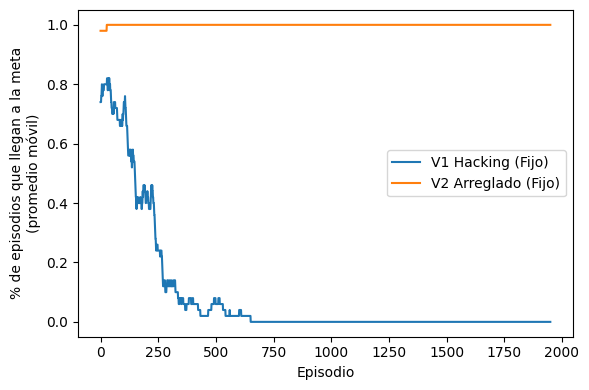

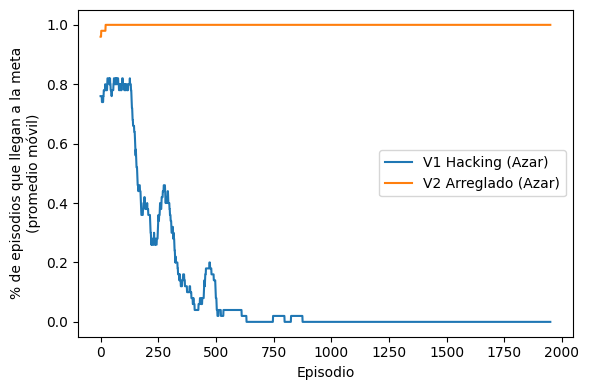

In [ ]:
# 1. Definimos las configuraciones
meta_fija = (5, 5)
monedas_fijas = ((0, 1), (1, 0), (1, 1))

meta_azar_comp = meta_actual
monedas_azar = monedas_actuales  # Las monedas generadas aleatoriamente antes

# 2. Función de entrenamiento actualizada para mostrar la info solicitada
def entrenar_comparativa(pos_meta, pos_monedas, nombre_suffix):
    global GOAL
    GOAL = pos_meta

    # V1: Mal especificado
    env_v1 = RewardHackingGridWorld(coin_positions=pos_monedas, coin_repeatable=True,
                                    coin_reward=1.0, goal_reward=10.0, step_cost=-0.01, max_steps=200)
    # V2: Bien especificado
    env_v2 = RewardHackingGridWorld(coin_positions=pos_monedas, coin_repeatable=False,
                                    coin_reward=1.0, goal_reward=25.0, step_cost=-0.05, max_steps=500)

    print(f"\n--- EXPERIMENTO: {nombre_suffix} (Meta: {pos_meta}) ---")

    # Entrenamiento V1
    _, reached1, rew1 = train(env_v1, n_episodes=2000)
    print(f"V1 (Hacking) - Monedas: {pos_monedas}")
    print(f"% de episodios (ultimos 200) que llegaron a la meta: {100*np.mean(reached1[-200:]):.1f}%")
    print(f"Recompensa promedio por episodio (ultimos 200):      {np.mean(rew1[-200:]):.2f}\n")

    # Entrenamiento V2
    _, reached2, rew2 = train(env_v2, n_episodes=2000)
    print(f"V2 (Arreglado) - Monedas: {pos_monedas}")
    print(f"% de episodios (ultimos 200) que llegaron a la meta: {100*np.mean(reached2[-200:]):.1f}%")
    print(f"Recompensa promedio por episodio (ultimos 200):      {np.mean(rew2[-200:]):.2f}")

    return reached1, reached2

# Ejecutamos los entrenamientos
reached_fijo_v1, reached_fijo_v2 = entrenar_comparativa(meta_fija, monedas_fijas, "CASO FIJO")
reached_azar_v1, reached_azar_v2 = entrenar_comparativa(meta_azar_comp, monedas_azar, "CASO ALEATORIO")

# 3. Visualización comparativa
plot_training_curves({
    "V1 Hacking (Fijo)": reached_fijo_v1,
    "V2 Arreglado (Fijo)": reached_fijo_v2,
})

plot_training_curves({
    "V1 Hacking (Azar)": reached_azar_v1,
    "V2 Arreglado (Azar)": reached_azar_v2
})

### Visualización de Políticas y Videos Comparativos

Aquí puedes ver cómo se comporta el agente en cada uno de los 4 escenarios entrenados.

Preparando visualizaciones...


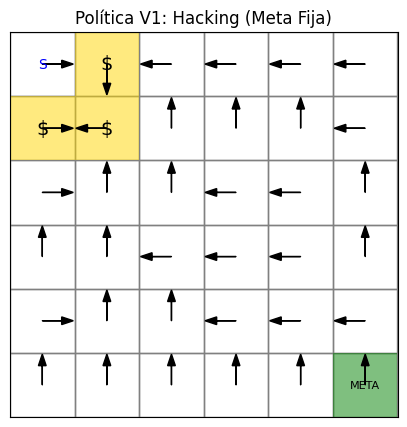

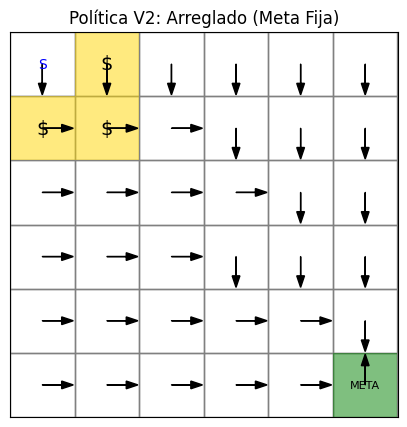

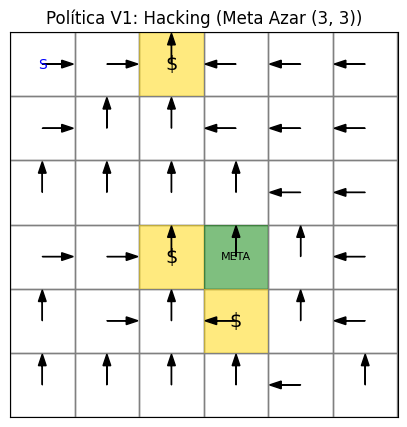

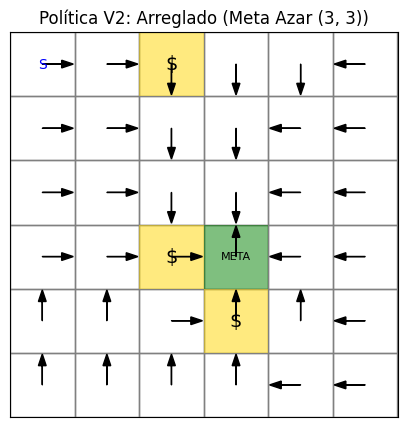

In [ ]:
# 1. Re-instanciamos los entornos para poder visualizar con sus metas y monedas correspondientes
env_fijo_v1 = RewardHackingGridWorld(goal_position=meta_fija, coin_positions=monedas_fijas, coin_repeatable=True, goal_reward=10.0, step_cost=-0.01, max_steps=200)
env_fijo_v2 = RewardHackingGridWorld(goal_position=meta_fija, coin_positions=monedas_fijas, coin_repeatable=False, goal_reward=25.0, step_cost=-0.05, max_steps=500)
env_azar_v1 = RewardHackingGridWorld(goal_position=meta_azar_comp, coin_positions=monedas_azar, coin_repeatable=True, goal_reward=10.0, step_cost=-0.01, max_steps=200)
env_azar_v2 = RewardHackingGridWorld(goal_position=meta_azar_comp, coin_positions=monedas_azar, coin_repeatable=False, goal_reward=25.0, step_cost=-0.05, max_steps=500)

# Entrenamos rápidamente los agentes para visualización (ya que necesitamos el objeto 'agent')
print("Preparando visualizaciones...")
agt_fijo_v1, _, _ = train(env_fijo_v1, n_episodes=2000)
agt_fijo_v2, _, _ = train(env_fijo_v2, n_episodes=2000)
agt_azar_v1, _, _ = train(env_azar_v1, n_episodes=2000)
agt_azar_v2, _, _ = train(env_azar_v2, n_episodes=2000)

# --- CASO FIJO ---
render_policy(agt_fijo_v1, env_fijo_v1, "Política V1: Hacking (Meta Fija)")
render_policy(agt_fijo_v2, env_fijo_v2, "Política V2: Arreglado (Meta Fija)")

# --- CASO ALEATORIO ---
render_policy(agt_azar_v1, env_azar_v1, f"Política V1: Hacking (Meta Azar {env_azar_v1.goal_position})")
render_policy(agt_azar_v2, env_azar_v2, f"Política V2: Arreglado (Meta Azar {env_azar_v2.goal_position})")

### Comparativa Visual: Agente V1 vs. Agente V2 (Entorno Aleatorio)

En esta sección grabamos el comportamiento final de ambos agentes.
* **V1 (Hacking):** Verás que se distrae infinitamente con las monedas dinámicas.
* **V2 (Arreglado):** Verás que, a pesar de las distracciones, prioriza llegar a la META.

In [ ]:
# Grabamos los videos usando los entornos y agentes entrenados para el caso aleatorio
record_episode_video(env_azar_v1, agt_azar_v1, "v1_azar_final.mp4", max_frames=env_azar_v1.max_steps, fps=6)
record_episode_video(env_azar_v2, agt_azar_v2, "v2_azar_final.mp4", max_frames=env_azar_v2.max_steps, fps=6)

print("Videos generados exitosamente.")

Videos generados exitosamente.


In [ ]:
import ipywidgets as widgets
from IPython.display import display

# Mostramos los videos comparativos lado a lado
video1 = widgets.Video.from_file("v1_azar_final.mp4", width=350, height=350)
video2 = widgets.Video.from_file("v2_azar_final.mp4", width=350, height=350)

label1 = widgets.HTML("<center><b>Agente V1: Reward Hacking (Azar)</b></center>")
label2 = widgets.HTML("<center><b>Agente V2: Arreglado (Azar)</b></center>")

display(widgets.HBox([
    widgets.VBox([label1, video1]),
    widgets.VBox([label2, video2])
]))

# 🚀 Estrategia de Entrenamiento e Iteración hacia la Configuración V2

### 1. Diagnóstico del Problema en la Configuración Base (V1)

En la versión inicial (**V1**), el entorno presentaba un caso claro de *specification gaming* / *reward hacking*:
* **`coin_repeatable = True`**: Las monedas en `(0,1), (1,0), (1,1)` eran infinitas y el agente podía recolectarlas una y otra vez en un mismo episodio.
* **`step_cost = -0.01`**: El costo por paso era insignificante, haciendo que deambular fuera casi gratuito.
* **`goal_reward = 10.0`** vs. **`max_steps = 200`**: Al alternar indefinidamente entre las monedas, el agente acumulaba hasta **~198 puntos**, superando por mucho los **+10 puntos** de completar la trayectoria hasta la meta.

**Resultados de V1:**
* **Tasa de éxito a la meta:** `0.0%`
* **Recompensa promedio acumulada:** `188.09` (métrica inflada artificialmente por la recolección circular de monedas).

---

### 2. Estrategia Experimental de Reespecificación (Paso a Paso)

Para alinear el comportamiento del agente sin eliminar el incentivo de las monedas como guía exploratoria, reajustamos los parámetros del entorno `RewardHackingGridWorld`:

1. **Eliminación del Farmeo Infinito (`coin_repeatable = False`)**:
   * *Efecto:* Al hacer que las monedas se agoten tras la primera recolección por episodio, se rompe estructuralmente la trampa de recompensa infinita.
2. **Dominancia de la Meta Principal (`goal_reward = 25.0`)**:
   * *Efecto:* Incrementamos la recompensa de la meta para garantizar que completar el mapa (+25 pts) sea categóricamente más valioso que recolectar las 3 monedas disponibles en total (+3 pts).
3. **Penalización por Ineficiencia Temporal (`step_cost = -1.0`)**:
   * *Efecto:* Aumentamos el costo por paso a -1.0. Esto penaliza severamente el deambular e incentiva al algoritmo $Q$-learning a encontrar la ruta más corta hacia la meta.
4. **Horizonte de Pasos (`max_steps = 500`)**:
   * *Efecto:* Al no existir monedas infinitas y existir un costo por paso real, aumentar el margen de pasos no provoca conductas patológicas y favorece la convergencia del aprendizaje.

---

### 3. Resultados Comparativos: Configuración V1 vs. Configuración V2

| Parámetro / Métrica | Configuración V1 (Mal especificada) | Configuración V2 (Reespecificada) | Impacto en el Aprendizaje |
| :--- | :---: | :---: | :--- |
| **`coin_repeatable`** | `True` | **`False`** | Elimina el ciclo infinito de recolección. |
| **`coin_reward`** | `1.0` | **`1.0`** | Mantiene la moneda como guía intermedia de ruta. |
| **`goal_reward`** | `10.0` | **`25.0`** | Invierte el valor relativo a favor del objetivo real. |
| **`step_cost`** | `-0.01` | **`-1.0`** | Penaliza la ineficiencia y fuerza el camino óptimo. |
| **`max_steps`** | `200` | **`500`** | Permite flexibilidad en la fase de exploración. |
| **Tasa de Éxito a la Meta** | **`0.0%`** | **`100.0%`** | Transición total hacia el cumplimiento de la tarea. |
| **Recompensa Promedio** | **`188.09`** | **`16.46`** | Métrica real de desempeño sin puntajes inflados. |

---

### 4. Evidencias de Validación

* **Mapa de Política (`render_policy`)**: Pasamos de un bucle cerrado atascado en las casillas `(0,1), (1,0), (1,1)` a un flujo de vectores que apunta directamente desde la casilla inicial $S(0,0)$ hasta la $META(5,5)$.
* **Curva de Aprendizaje (`plot_training_curves`)**: Mientras que la curva de V1 caía al 0% a medida que el agente aprendía a explotar el entorno, la curva de V2 sube rápidamente y se estabiliza de forma persistente en el **100%** de éxito.
* **Comportamiento Cualitativo (Video `agente_v2.mp4`)**: Muestra al agente realizando un recorrido eficiente y limpio hacia la meta, recogiendo monedas de paso sin detenerse.